In [36]:
# function 파일 오류 수정 후 런타임을 재시작하지 않고 수정내용을 반영하는 방법
import importlib
import multiclass_functions
importlib.reload(multiclass_functions)

from multiclass_functions import *

In [37]:
import torch
from torch import nn, optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms, datasets
import matplotlib.pyplot as plt
import numpy as np
import os
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [38]:
BATCH_SIZE = 32
LR = 1e-3
EPOCH = 15
criterion = nn.CrossEntropyLoss()
new_model_train = True

model_type = 'MLP_drop'
dataset = 'CIFAR10'

save_dir = 'results'
os.makedirs(save_dir, exist_ok=True)

save_model_path = f'{save_dir}/{model_type}_{dataset}.pt'

In [39]:
transform_train = transforms.Compose([
    transforms.AutoAugment(transforms.AutoAugmentPolicy.CIFAR10),
    transforms.ToTensor()
])
transform_test = transforms.ToTensor()
train_DS = datasets.CIFAR10(root='data', train=True, transform=transform_train, download=True)
test_DS = datasets.CIFAR10(root='data', train=False, transform=transform_test, download=True)

train_DL = DataLoader(train_DS, batch_size= BATCH_SIZE, shuffle=True)
test_DL = DataLoader(test_DS, batch_size=BATCH_SIZE, shuffle=True)

In [40]:
x_batch, y_batch = next(iter(train_DL))
print(x_batch.shape)

torch.Size([32, 3, 32, 32])


In [41]:
class CNN(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(
            nn.Conv2d(3,8,3, padding=1),    # input(32,3,32,32)
            nn.BatchNorm2d(8),
            nn.ReLU()
            )
        self.maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(
            nn.Conv2d(8,16,3),
            nn.BatchNorm2d(16),
            nn.ReLU()
            )
        self.maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(
            nn.Conv2d(16,32,3),
            nn.BatchNorm2d(32),
            nn.ReLU()
            )
        self.maxpool3 = nn.MaxPool2d(2)
        self.fc = nn.Linear(32*2*2, 10)

    def forward(self, x, *args, **kwargs):
        x = self.conv1(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = self.conv3(x)
        x = self.maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

class MLP_drop(nn.Module):
  def __init__(self):
    super().__init__()
    self.linear = nn.Sequential(
        nn.Linear(3*32*32, 512),  
        nn.BatchNorm1d(512),  
        nn.ReLU(),
        nn.Linear(512, 256),
        nn.BatchNorm1d(256),
        nn.Dropout(p=.3),
        nn.Linear(256, 10)
    )

  def forward(self, x):
    x = torch.flatten(x, start_dim=1)
    x = self.linear(x)
    return x

class CNN_drop(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.conv1 = nn.Sequential(
            nn.Conv2d(3,8,3, padding=1),
            nn.BatchNorm2d(8),
            nn.ReLU(),
            nn.Dropout(p=.2)
            )
        self.maxpool1 = nn.MaxPool2d(2)
        self.conv2 = nn.Sequential(
            nn.Conv2d(8,16,3),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.Dropout(p=.2)
            )
        self.maxpool2 = nn.MaxPool2d(2)
        self.conv3 = nn.Sequential(
            nn.Conv2d(16,32,3),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.Dropout(p=.2)
            )
        self.maxpool3 = nn.MaxPool2d(2)
        self.fc = nn.Linear(32*2*2, 10)

    def forward(self, x, *args, **kwargs):
        x = self.conv1(x)
        x = self.maxpool1(x)
        x = self.conv2(x)
        x = self.maxpool2(x)
        x = self.conv3(x)
        x = self.maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

class CNN_deep(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args,**kwargs)
        self.conv_block1 = nn.Sequential(nn.Conv2d(3,32,3, padding=1),
                                         nn.BatchNorm2d(32),
                                         nn.ReLU(),
                                         nn.Conv2d(32,32,3, padding=1),
                                         nn.BatchNorm2d(32),
                                         nn.ReLU())
        self.maxpool1 = nn.MaxPool2d(2)

        self.conv_block2 = nn.Sequential(nn.Conv2d(32,64,3, padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU(),
                                         nn.Conv2d(64,64,3, padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU(),
                                         nn.Conv2d(64,64,3, padding=1),
                                         nn.BatchNorm2d(64),
                                         nn.ReLU())

        self.maxpool2 = nn.MaxPool2d(2)
        
        self.conv_block3 = nn.Sequential(nn.Conv2d(64,128,3, padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU(),
                                         nn.Conv2d(128,128,3, padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU(),
                                         nn.Conv2d(128,128,3, padding=1),
                                         nn.BatchNorm2d(128),
                                         nn.ReLU())

        self.maxpool3 = nn.MaxPool2d(2)

        self.fc = nn.Sequential(nn.Linear(128*4*4,512),
                                nn.ReLU(),
                                nn.Linear(512, 10))

    def forward(self, x, *args, **kwargs):
        x = self.conv_block1(x)
        x = self.maxpool1(x)
        x = self.conv_block2(x)
        x = self.maxpool2(x)
        x = self.conv_block3(x)
        x = self.maxpool3(x)
        x = torch.flatten(x, start_dim=1)
        x = self.fc(x)
        return x

In [42]:
model = globals()[model_type]().to(device)

model.eval()
with torch.no_grad():
    print(model(x_batch.to(device)).shape)

torch.Size([32, 10])


Epoch : 1, train loss : 2.012
--------------------
Epoch : 2, train loss : 1.865
--------------------
Epoch : 3, train loss : 1.801
--------------------
Epoch : 4, train loss : 1.757
--------------------
Epoch : 5, train loss : 1.726
--------------------
Epoch : 6, train loss : 1.688
--------------------
Epoch : 7, train loss : 1.674
--------------------
Epoch : 8, train loss : 1.640
--------------------
Epoch : 9, train loss : 1.628
--------------------
Epoch : 10, train loss : 1.599
--------------------
Epoch : 11, train loss : 1.583
--------------------
Epoch : 12, train loss : 1.570
--------------------
Epoch : 13, train loss : 1.543
--------------------
Epoch : 14, train loss : 1.532
--------------------
Epoch : 15, train loss : 1.513
--------------------


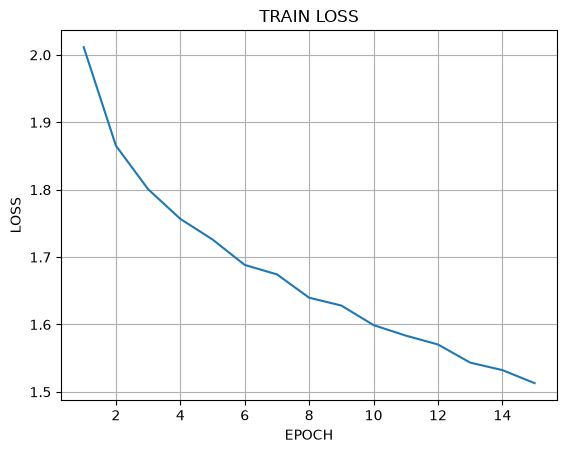

In [43]:
if new_model_train:
    optimizer = optim.Adam(model.parameters(), lr=LR)
    loss_history = Train(model, train_DL, criterion, optimizer, EPOCH)

    torch.save(model, save_model_path)

    plt.figure()
    plt.plot(range(1, EPOCH+1), loss_history)
    plt.xlabel('EPOCH')
    plt.ylabel('LOSS')
    plt.title('TRAIN LOSS')
    plt.grid()

In [44]:
load_model = torch.load(save_model_path, map_location= device, weights_only=False)

In [45]:
Test(load_model, test_DL)
print(count_params(load_model))

# dropout 이전 accuracy : 76.4 %
# CNN_drop 이후 accuracy : 55.2 %
# MLP_drop 이후 accuracy : 52.8 %

Test accuracy : 5193 / 10000 (51.9 %)
1708810


In [ ]:
# 결국은 Test_DL 이 아닌 dataloader를 받는 새로운 함수 생성
Accuracy(load_model, train_DL, 'Train') # 48.4 %
Accuracy(load_model, test_DL, 'Test')   # 51.9 %
print(count_params(load_model))

Train Accuracy : 24185 / 50000 (48.4 %)
Test Accuracy : 5193 / 10000 (51.9 %)
1708810


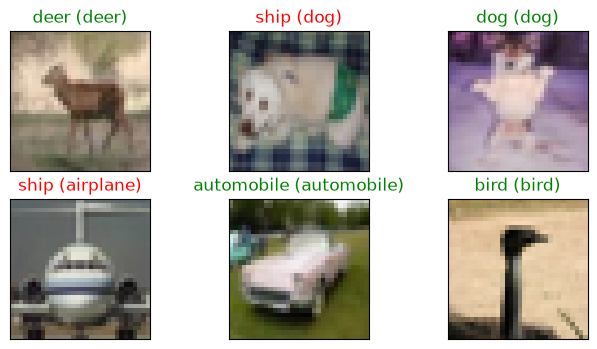

In [47]:
Test_plot(load_model, test_DL)

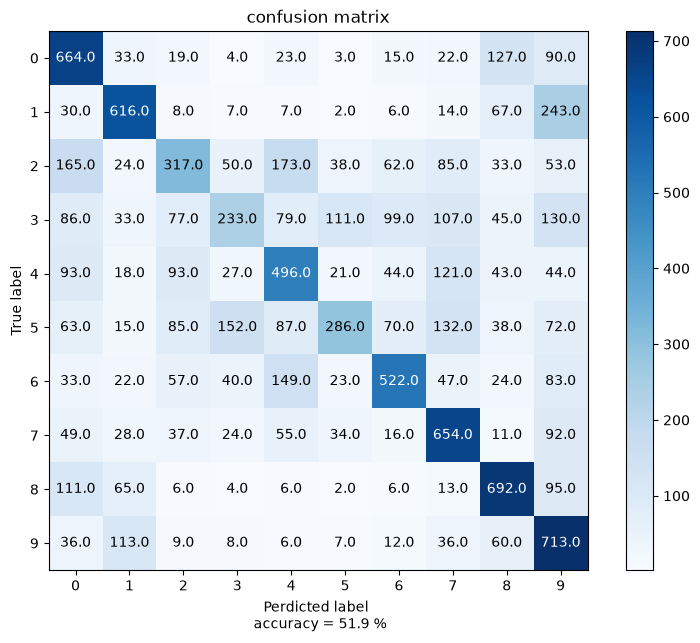

In [48]:
confusion = get_conf(load_model, test_DL)

plot_confusion_matrix(confusion)